# Instructor Effectiveness Modeling

### Accredian – Data Science Internship Screening Assignment

**Candidate:** Sweti Yadav  
**Role:** Data Science / AI Content Specialist Intern

---

## Problem Statement

The objective of this assignment is to analyze batch-level learner outcomes,
engagement, and feedback data to estimate instructor effectiveness.

The analysis involves:
- Exploratory Data Analysis
- Defining an Instructor Effectiveness Score
- Aggregating batch-level data to instructor level
- Creating instructor effectiveness tiers
- Building a machine learning classification model
- Evaluating and interpreting the model
- Discussing limitations and real-world applicability

## 1. Objective

The main objective is to estimate instructor effectiveness using learner
outcomes, engagement metrics, and learner feedback.

The analysis will:

1. Explore the dataset and identify important patterns.
2. Define a transparent Instructor Effectiveness Score.
3. Aggregate batch-level metrics to instructor level.
4. Categorize instructors into Low, Medium, and High effectiveness tiers.
5. Train a classical machine learning model to predict effectiveness tiers.
6. Evaluate the model using appropriate classification metrics.
7. Interpret the important factors influencing instructor effectiveness.
8. Discuss limitations, confounding factors, and ethical considerations.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.preprocessing import StandardScaler

In [ ]:
file_path = "/content/instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [ ]:
print("Shape of dataset:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Shape of dataset: (2000, 12)

First 5 rows:


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710



Column names:
['batch_id', 'instructor_id', 'course_id', 'completion_rate', 'avg_score_improvement', 'avg_quiz_score', 'dropout_rate', 'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate']


## 2. Dataset Overview

Each row represents one course batch. Multiple batches can belong to the
same instructor.

The dataset contains:
- Instructor identifiers
- Course and batch identifiers
- Learner outcome metrics
- Engagement metrics
- Feedback metrics

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
completion_rate,2000.0,0.602808,0.159667,0.300000,0.489260,0.603091,0.712797,0.980000
avg_score_improvement,2000.0,27.035844,5.716641,6.159240,23.124673,26.938629,30.885600,40.000000
avg_quiz_score,2000.0,77.956126,10.695618,40.386725,70.897590,78.020567,85.444286,100.000000
dropout_rate,2000.0,0.394883,0.162747,0.020000,0.280035,0.394820,0.511432,0.700000
avg_watch_time,2000.0,0.776515,0.145231,0.287440,0.675076,0.780330,0.894242,1.000000
assignment_submission_rate,2000.0,0.753188,0.148058,0.251111,0.652110,0.756380,0.856458,1.000000
forum_activity_rate,2000.0,0.250300,0.100640,0.000000,0.179845,0.249771,0.319204,0.641111
avg_feedback_score,2000.0,4.207134,0.419209,2.639915,3.918986,4.205989,4.503437,5.000000
feedback_response_rate,2000.0,0.736519,0.149412,0.259935,0.633293,0.737213,0.845876,1.000000


## 3. Data Quality Check

Before performing analysis, missing values, duplicate records, and unusual
values are checked to ensure data quality.

In [ ]:
missing_values = df.isnull().sum()

print("Missing values:")
display(missing_values)

Missing values:


,0
batch_id,0
instructor_id,0
course_id,0
completion_rate,0
avg_score_improvement,0
avg_quiz_score,0
dropout_rate,0
avg_watch_time,0
assignment_submission_rate,0
forum_activity_rate,0


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [ ]:
print("Number of unique instructors:", df["instructor_id"].nunique())
print("Number of unique courses:", df["course_id"].nunique())
print("Number of batches:", df["batch_id"].nunique())

Number of unique instructors: 120
Number of unique courses: 25
Number of batches: 2000


In [ ]:
batch_counts = df.groupby("instructor_id").size()

print(batch_counts.describe())

count    120.000000
mean      16.666667
std        4.582270
min        7.000000
25%       13.750000
50%       17.000000
75%       19.000000
max       31.000000
dtype: float64


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of
learner outcomes, engagement, and feedback metrics and to identify
relationships between these variables.

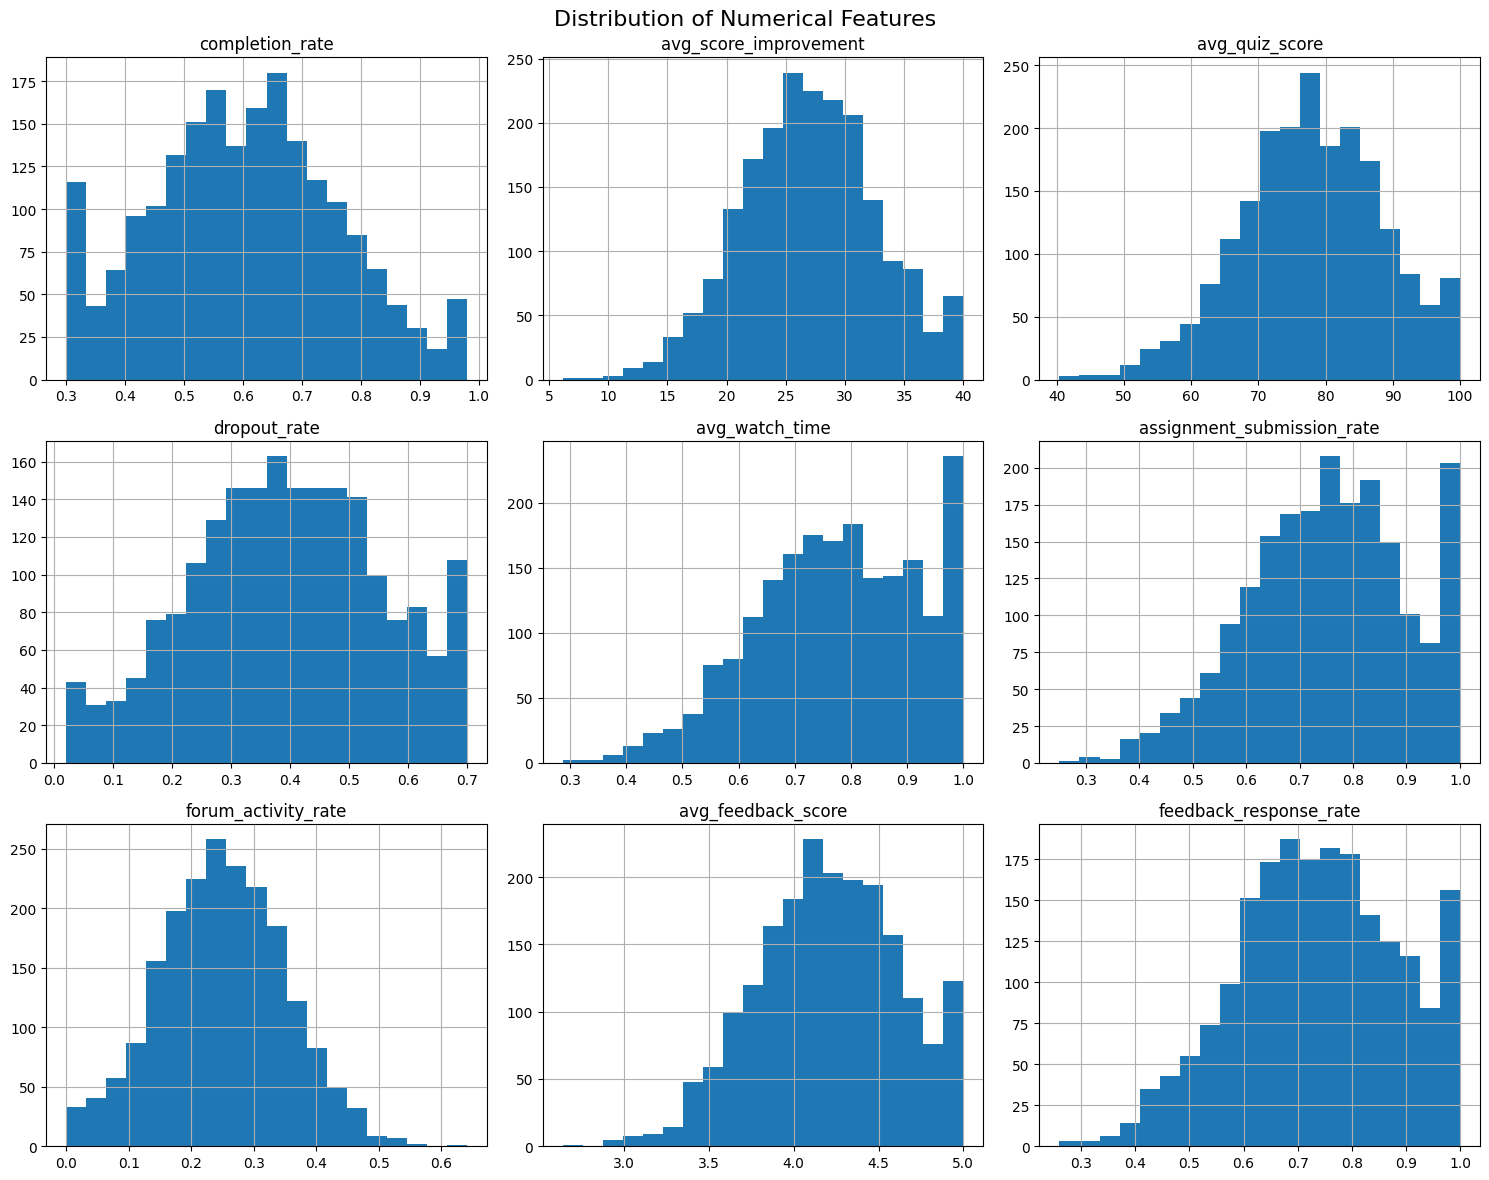

In [ ]:
numeric_cols = [
    "completion_rate",
    "avg_score_improvement",
    "avg_quiz_score",
    "dropout_rate",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "feedback_response_rate"
]

df[numeric_cols].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### EDA Observations

- Completion rate is generally concentrated around the middle-to-high range.
- Average score improvement is mostly centered around moderate values.
- Average quiz score shows a concentration toward higher scores.
- Dropout rate is mostly concentrated at lower to moderate levels.
- Average watch time is generally high across batches.
- Assignment submission rate is mostly concentrated toward higher values.
- Forum activity rate is relatively low compared with other engagement metrics.
- Average feedback score is concentrated around the higher range.
- Feedback response rate is generally moderate to high.

These distributions indicate that the dataset contains meaningful variation
across learner outcomes, engagement, and feedback metrics, making them suitable
for further analysis.

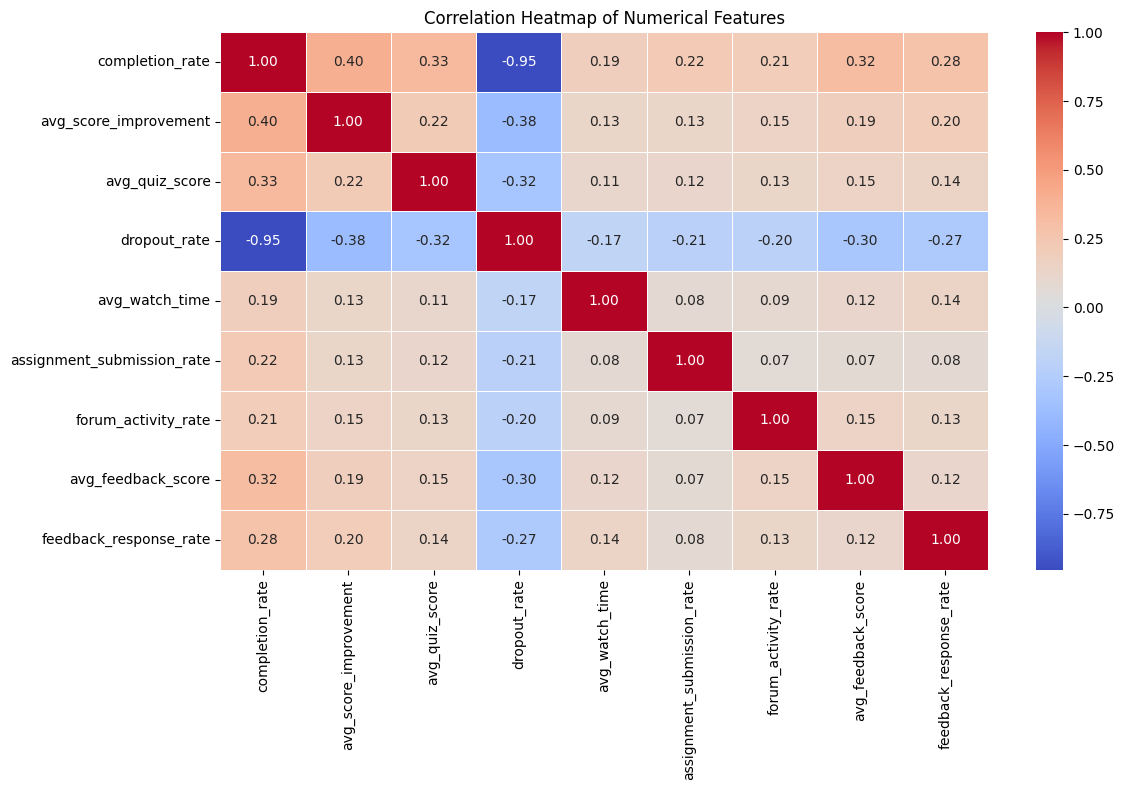

In [ ]:
plt.figure(figsize=(12, 8))

corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## 5. Instructor Effectiveness Score

An Instructor Effectiveness Score is created using learner outcomes,
engagement, and feedback metrics.

The metrics are normalized before combining them because they have
different scales. Higher dropout rate is treated as a negative factor.


In [ ]:
from sklearn.preprocessing import MinMaxScaler

score_metrics = [
    "completion_rate",
    "avg_score_improvement",
    "avg_quiz_score",
    "dropout_rate",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "feedback_response_rate"
]

scaler = MinMaxScaler()

scaled_data = pd.DataFrame(
    scaler.fit_transform(df[score_metrics]),
    columns=score_metrics
)

# Dropout is a negative indicator, so invert it
scaled_data["dropout_rate"] = 1 - scaled_data["dropout_rate"]

scaled_data.head()

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,0.000000,0.238373,0.556249,7.731867e-02,0.683637,0.720811,0.169103,0.477227,0.369235
1,0.525324,0.493839,0.619419,4.042678e-01,0.291198,0.998085,0.437599,1.000000,0.640690
2,0.000000,0.293382,0.657185,-2.220446e-16,0.968987,0.742683,0.322898,0.371797,0.569542
3,0.499274,0.534901,0.988179,5.372689e-01,0.784601,0.391839,0.477913,0.664240,1.000000
4,0.334267,0.736459,0.989825,2.630895e-01,0.884150,0.820915,0.393519,0.756886,0.590184


In [ ]:
instructor_data = pd.concat(
    [df[["instructor_id"]], scaled_data],
    axis=1
)

instructor_data = instructor_data.groupby("instructor_id").mean()

instructor_data["batch_count"] = df.groupby("instructor_id").size()

instructor_data.head()

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,batch_count
instructor_id,,,,,,,,,,
I_001,0.358658,0.605253,0.646055,0.337363,0.672327,0.635317,0.375209,0.668547,0.587682,25
I_002,0.633639,0.709411,0.693645,0.665891,0.771799,0.698745,0.451731,0.721621,0.708591,20
I_003,0.688892,0.703843,0.691192,0.684076,0.745203,0.705706,0.462047,0.766972,0.746147,18
I_004,0.232836,0.495047,0.625592,0.224616,0.709681,0.677277,0.352917,0.608662,0.623627,17
I_005,0.823158,0.780993,0.762270,0.815098,0.785317,0.835679,0.520220,0.662095,0.708399,19


In [ ]:
instructor_data["outcome_score"] = (
    instructor_data["completion_rate"] +
    instructor_data["avg_score_improvement"] +
    instructor_data["avg_quiz_score"] +
    instructor_data["dropout_rate"]
) / 4

instructor_data["engagement_score"] = (
    instructor_data["avg_watch_time"] +
    instructor_data["assignment_submission_rate"] +
    instructor_data["forum_activity_rate"]
) / 3

instructor_data["feedback_score"] = (
    instructor_data["avg_feedback_score"] +
    instructor_data["feedback_response_rate"]
) / 2

instructor_data["effectiveness_score"] = (
    0.40 * instructor_data["outcome_score"] +
    0.30 * instructor_data["engagement_score"] +
    0.30 * instructor_data["feedback_score"]
)

instructor_data[[
    "outcome_score",
    "engagement_score",
    "feedback_score",
    "effectiveness_score"
]].head()

,outcome_score,engagement_score,feedback_score,effectiveness_score
instructor_id,,,,
I_001,0.486832,0.560951,0.628114,0.551453
I_002,0.675646,0.640758,0.715106,0.677018
I_003,0.692001,0.637652,0.756559,0.695064
I_004,0.394523,0.579959,0.616145,0.516640
I_005,0.795380,0.713739,0.685247,0.737848


In [ ]:
instructor_data["effectiveness_tier"] = pd.qcut(
    instructor_data["effectiveness_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

print(instructor_data["effectiveness_tier"].value_counts())

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64


## 6. Machine Learning Model

A classification model is trained at the instructor level to predict
Low, Medium, and High effectiveness tiers.

In [ ]:
X = instructor_data.drop(
    columns=[
        "effectiveness_tier",
        "effectiveness_score",
        "outcome_score",
        "engagement_score",
        "feedback_score"
    ]
)

y = instructor_data["effectiveness_tier"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (120, 10)
Target shape: (120,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 96
Testing samples: 24


## 7. Model Training

A Random Forest Classifier is used to predict instructor effectiveness tiers.

In [ ]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed.")

Model training completed.


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1 Score : {f1:.3f}")

Accuracy : 0.958
Precision: 0.963
Recall   : 0.958
F1 Score : 0.958


In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         8
         Low       1.00      0.88      0.93         8
      Medium       0.89      1.00      0.94         8

    accuracy                           0.96        24
   macro avg       0.96      0.96      0.96        24
weighted avg       0.96      0.96      0.96        24



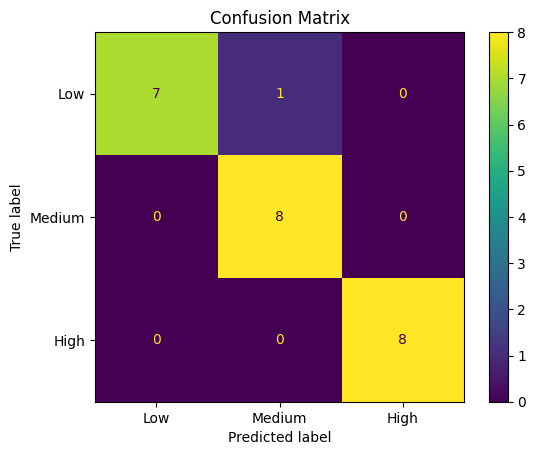

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

## 8. Feature Importance

Feature importance from the Random Forest model is used to identify which
instructor-level variables contribute most to predicting effectiveness tiers.

In [ ]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

completion_rate               0.266664
dropout_rate                  0.184728
feedback_response_rate        0.177735
avg_score_improvement         0.095097
avg_quiz_score                0.088944
avg_feedback_score            0.083507
forum_activity_rate           0.035052
avg_watch_time                0.030145
assignment_submission_rate    0.025716
batch_count                   0.012411
dtype: float64


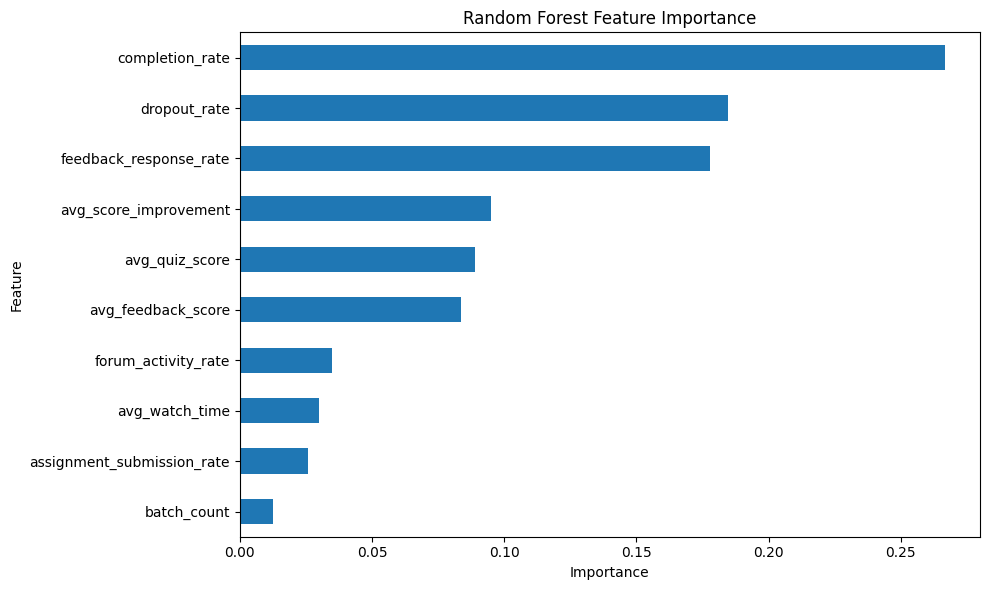

In [ ]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 9. Mandatory Analysis Questions

### 1. Which features appear most influential in predicting instructor effectiveness?

Completion rate is the most influential feature, followed by dropout rate and
feedback response rate. These features are important because they reflect
learner completion, learner retention, and feedback engagement.

### 2. Which variables could be misleading or confounded?

Course difficulty, learner background, batch composition, and feedback response
bias may influence the observed metrics. Therefore, these variables should not
be interpreted as direct measures of instructor quality.

### 3. What are potential failure modes of the model?

The model may perform poorly for new instructors, small sample sizes, unusual
courses, or batches with different learner characteristics. The effectiveness
tiers are also based on a constructed scoring rule.

### 4. What additional data would improve the analysis?

Useful additional data could include instructor experience, course difficulty,
batch size, learner prior knowledge, attendance, assignment quality, and
structured teaching evaluations.

### 5. Should this model be used as the sole basis for instructor evaluation?

No. The model should be used as a decision-support tool rather than the sole
basis for evaluating instructors because learner outcomes are affected by
multiple factors beyond instructor performance.

## 10. Limitations and Ethical Considerations

- The dataset contains only 120 instructors and 2,000 batches.
- Effectiveness tiers are based on a manually defined scoring methodology.
- Correlation does not imply causation.
- Learner and course characteristics may affect the observed outcomes.
- The model should not be used as the sole basis for employment or performance
  decisions.
- Instructor evaluation should include human review and contextual information.

## 11. Conclusion

The analysis developed an Instructor Effectiveness Score using learner
outcomes, engagement, and feedback metrics. Instructors were categorized into
Low, Medium, and High effectiveness tiers, followed by a Random Forest
classification model.

The model achieved a macro F1-score of 0.958 on the test set. Completion rate,
dropout rate, and feedback response rate were the most influential features.
The results should be interpreted as decision support rather than a definitive
measure of instructor quality.